# Архитектуры CNN и перенос обучения. Доменный сдвиг

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**  
**Вариант: 11**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "06_transfer_domain"
OUT.mkdir(exist_ok=True, parents=True)

## Данные и три стратегии обучения

Использую небольшую стратифицированную выборку MNIST. Сравниваю CNN с нуля, MobileNetV3-Small с замороженными весами ImageNet и дообучение последнего блока. Для MobileNet перевожу изображения в RGB, 224×224 и применяю нормализацию ImageNet. Код — в vision.py.

MNIST subset: 400 200 200 shape (400, 1, 28, 28)
Точные совпадения train/val/test: 0 0
Числа классов train: [40 47 35 40 35 42 41 37 36 47]


,model,accuracy,macro_f1,trainable_parameters,seconds
0,scratch_CNN,0.830,0.82363,2698,0.56676
1,frozen_backbone,0.790,0.79199,5770,102.68372
2,fine_tuning,0.865,0.86830,62218,102.06543


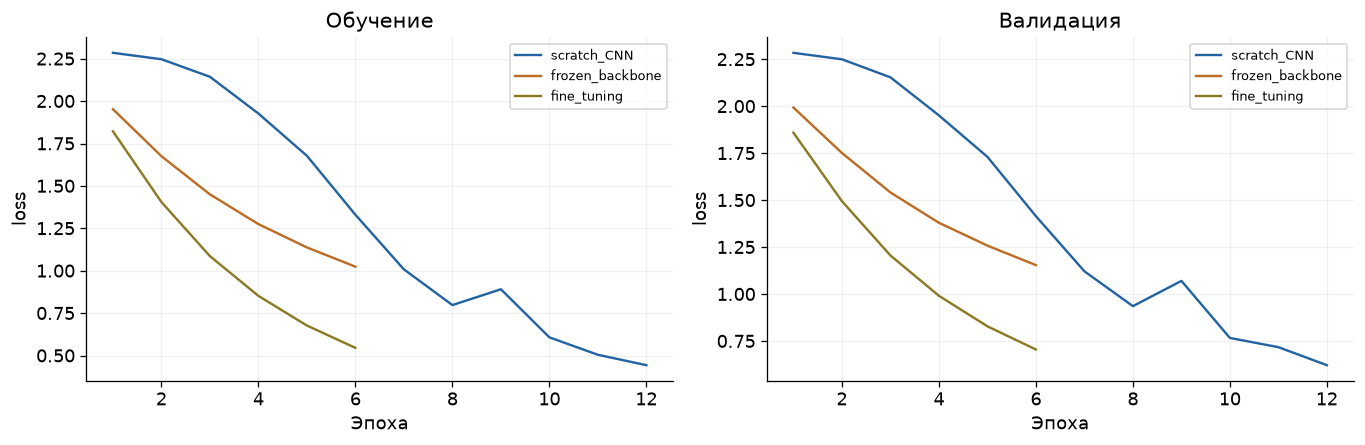

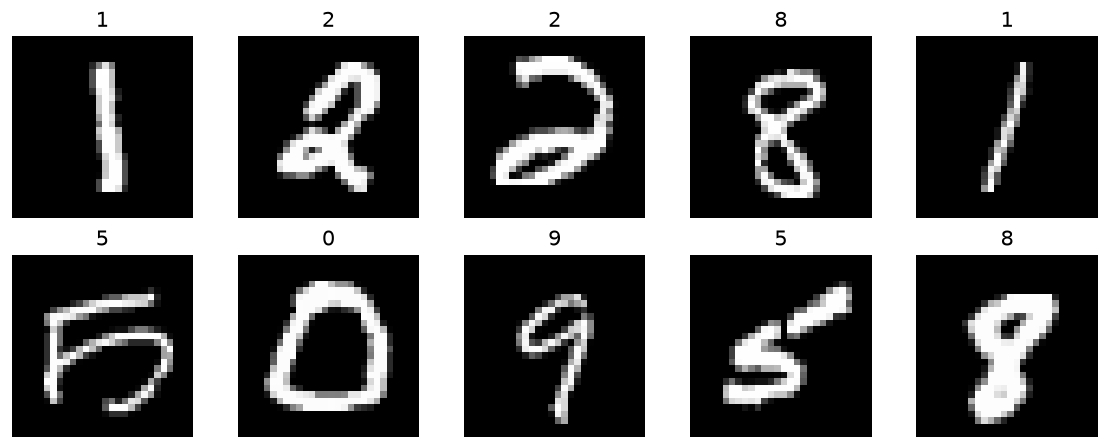

In [2]:
from vision import transfer_experiment

result = transfer_experiment(OUT)

## Вариант 11. Фон, освещение и тип изображения

Шесть условий: исходные изображения, затемнение, осветление, другой фон, размытие и шум. Форма цифры и метка сохраняются. Все проверки делаю на одном test без подбора параметров по нему.

,model,condition,accuracy,macro_f1,accuracy_drop
0,scratch_CNN,clean,0.795,0.77895,0.000
1,scratch_CNN,dark,0.645,0.60630,0.150
2,scratch_CNN,bright,0.720,0.71003,0.075
3,scratch_CNN,gray_background,0.200,0.09915,0.595
4,scratch_CNN,blur,0.765,0.75466,0.030
5,scratch_CNN,noise,0.770,0.76637,0.025
6,frozen_backbone,clean,0.825,0.82896,0.000
7,frozen_backbone,dark,0.800,0.81383,0.025
8,frozen_backbone,bright,0.805,0.81904,0.020
9,frozen_backbone,gray_background,0.800,0.80219,0.025


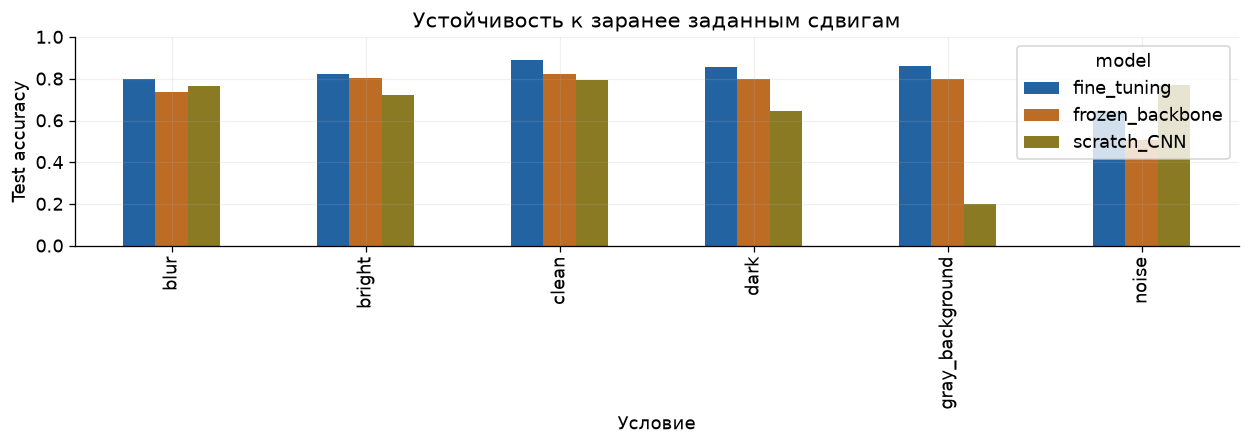

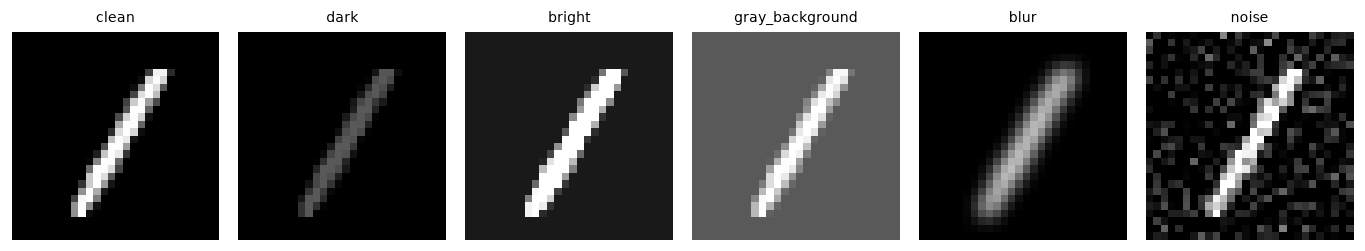

Наибольшее измеренное падение: scratch_CNN, условие gray_background, Δaccuracy=0.595. Изменение яркости/фона меняет статистику входа, сохраняя смысловую метку цифры. Синтетические сдвиги представляют контролируемую проверку; реальные камеры дополнительно меняют шум, цвет и резкость.

In [3]:
from vision import domain_evaluation

domain_evaluation(result, OUT)

## Эмбеддинги, поиск похожих примеров и ошибки

Строю PCA-проекцию и ищу ближайшие train-изображения по эмбеддингам. Сравниваю точность поиска и ошибки моделей.

Nearest-train retrieval accuracy: 0.865 cosine examples: [[0.79724526 0.5926053  0.573369  ]
 [0.95087755 0.64619553 0.56906426]
 [0.60875696 0.8629651  0.8428382 ]]


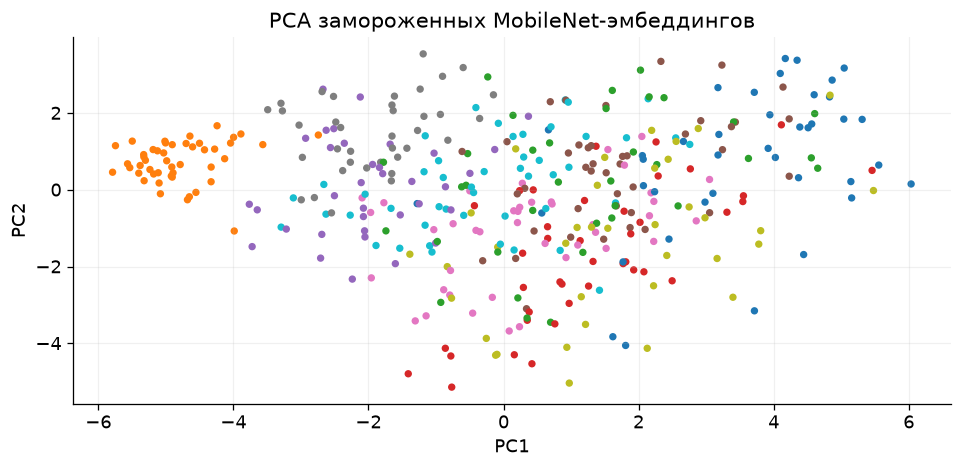

,index,true,predicted,confidence
0,2,3,5,0.31262
1,19,6,0,0.29155
2,30,0,6,0.48810
3,44,3,5,0.37243
4,50,7,2,0.29827
5,55,4,9,0.31380
6,77,0,5,0.57690
7,79,3,5,0.38131
8,80,3,5,0.42238
9,98,9,0,0.37136


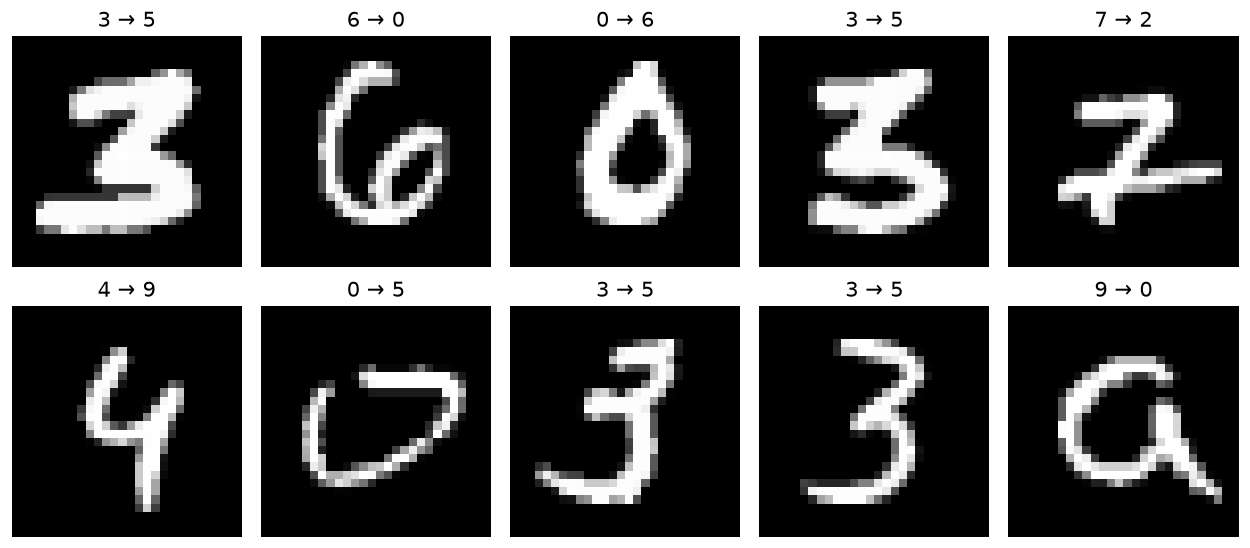

PCA может искажать соседство, поэтому дополнительно считаю точность поиска ближайшего изображения. Похожие цифры, неполные штрихи и разная толщина линий дают ошибки.

AlexNet и VGG развивают последовательные свёрточные блоки; Inception объединяет ветви разных масштабов; ResNet использует остаточные связи; DenseNet передаёт признаки последующим блокам. В практическом сравнении выбран компактный MobileNetV3 для ограниченного CPU-бюджета. Предобучение ImageNet не гарантирует превосходства на цифрах MNIST: исходный и целевой домены существенно различаются.

In [4]:
from vision import embedding_analysis

embedding_analysis(result, OUT)
note(
    "AlexNet и VGG развивают последовательные свёрточные блоки; Inception объединяет ветви разных масштабов; ResNet использует остаточные связи; DenseNet передаёт признаки последующим блокам. В практическом сравнении выбран компактный MobileNetV3 для ограниченного CPU-бюджета. Предобучение ImageNet не гарантирует превосходства на цифрах MNIST: исходный и целевой домены существенно различаются."
)

## Ответы на контрольные вопросы

1. Residual connection создаёт прямой путь передачи сигнала и градиента, упрощая обучение остаточного преобразования.

2. Feature extraction замораживает backbone и обучает новую голову; fine-tuning изменяет часть или все предобученные веса.

3. Близость означает сходство в признаках выбранной модели и метрики; семантическое соответствие требует проверки.

4. t-SNE нелинейно искажает расстояния и зависит от гиперпараметров; кластерная картинка не является строгой оценкой классификации или поиска.

5. Сдвиг фона, освещения или камеры меняет статистику входа и вызывает новые систематические ошибки.